# Philadelphia Crime Dataset — Exploratory Data Analysis

This notebook presents a reproducible descriptive analysis of the combined Philadelphia crime incident records for 2018–2022. Results are calculated from the supplied combined file. The analysis describes recorded counts and data characteristics; it does not infer causes or population-level risk.

## 1. Objective

The objective is to inspect the combined dataset, assess its basic data quality, and describe temporal, crime-type, district, PSA, and geographic distributions. The analyses follow common exploratory steps used in crime-data studies while relying only on this project’s records. No modeling or preprocessing for modeling is performed.

## 2. Dataset Overview

The combined file is expected under `dataset/processed/`. The notebook reports its dimensions, columns, data types, missingness, and sample records. Crime dates, incident classifications, district/PSA codes, and coordinates are used only when those columns are present. Object identifiers and incident keys are treated as identifiers, not continuous measurements.

## 3. Import Libraries

The libraries below support tabular analysis and static visualizations. No external services or additional package installation are required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from _bootstrap import ensure_project_root
except ModuleNotFoundError:
    from notebooks._bootstrap import ensure_project_root
project_root = ensure_project_root()
from src.config import COMBINED_DATASET
from src.data_loader import load_combined_philadelphia_data
from src.data_validation import (check_duplicates, check_missing_values,
                                 check_numeric_validity, get_class_distribution,
                                 inspect_schema)
from src.visualization import (plot_ordered_counts, plot_temporal_heatmap,
                               plot_geographic_hexbin, plot_correlation_heatmap)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")
FIGSIZE = (11, 5)


## 4. Load Dataset

The path is project-relative. If the exact expected name is absent, the notebook accepts one uniquely matching combined CSV in `dataset/processed/`; it never reads raw yearly files or changes the source file.

In [2]:
df = load_combined_philadelphia_data(low_memory=False)
analysis = df.copy()
print("Loaded:", COMBINED_DATASET)
print("Shape:", df.shape)


Loaded: D:\major project\dataset\processed\Philadelphia_Crime_Incidents_2018_2022_Combined.csv
Shape: (736033, 20)


## 5. Basic Dataset Inspection

The following cells show small reproducible samples and a compact column profile. The complete dataset is not printed.

In [3]:
display(df.head())
display(df.tail())
display(df.sample(n=min(5, len(df)), random_state=42))
print("Shape:", df.shape)
df.info(memory_usage="deep")


,source_year,objectid,dc_dist,psa,dispatch_date_time,dispatch_date,dispatch_time,hour,dc_key,location_block,ucr_general,text_general_code,point_x,point_y,gdb_geomattr_data,lat,lng,the_geom,cartodb_id,the_geom_webmercator
0,2018,119,39,2,2018-05-11 04:00:00+00,2018-05-11,00:00:00,22.0,2.010391e+11,2100 BLOCK WINDRIM,100,Homicide - Criminal,-75.159510,40.022313,NaN,40.022313,-75.159510,NaN,NaN,NaN
1,2018,18377,8,1,2018-05-25 04:00:00+00,2018-05-25,00:00:00,11.0,2.018080e+11,8100 BLOCK CRESCO AV,100,Homicide - Criminal,-75.029052,40.048675,NaN,40.048675,-75.029052,NaN,NaN,NaN
2,2018,20003,15,2,2018-06-28 04:00:00+00,2018-06-28,00:00:00,18.0,2.018150e+11,1900 BLOCK E CHELTENHAM AV,100,Homicide - Criminal,-75.065510,40.018049,NaN,40.018049,-75.065510,NaN,NaN,NaN
3,2018,20014,5,3,2018-08-06 04:00:00+00,2018-08-06,00:00:00,18.0,2.018050e+11,4500 BLOCK WILDE ST,100,Homicide - Criminal,-75.225237,40.028996,NaN,40.028996,-75.225237,NaN,NaN,NaN
4,2018,20023,12,3,2018-08-18 04:00:00+00,2018-08-18,00:00:00,20.0,2.018121e+11,5200 BLOCK WOODLAND AV,100,Homicide - Criminal,-75.216455,39.938066,NaN,39.938067,-75.216455,NaN,NaN,NaN


,source_year,objectid,dc_dist,psa,dispatch_date_time,dispatch_date,dispatch_time,hour,dc_key,location_block,ucr_general,text_general_code,point_x,point_y,gdb_geomattr_data,lat,lng,the_geom,cartodb_id,the_geom_webmercator
736028,2022,3282598,22,2,2022-11-11 15:12:00+00,2022-11-11,10:12:00,10.0,2.022221e+11,2800 BLOCK W GLENWOOD AV,700,Motor Vehicle Theft,NaN,NaN,NaN,NaN,NaN,NaN,3282599.0,NaN
736029,2022,3282600,26,3,2022-12-19 16:24:00+00,2022-12-19,11:24:00,11.0,2.022260e+11,2500 BLOCK E BOSTON ST,700,Motor Vehicle Theft,NaN,NaN,NaN,NaN,NaN,NaN,3282601.0,NaN
736030,2022,3282601,12,1,2022-12-08 23:58:00+00,2022-12-08,18:58:00,18.0,2.022121e+11,3100 BLOCK S 84th St,700,Motor Vehicle Theft,NaN,NaN,NaN,NaN,NaN,NaN,3282602.0,NaN
736031,2022,3282607,35,2,2022-08-30 20:32:00+00,2022-08-30,16:32:00,16.0,2.022351e+11,5200 BLOCK WESTFORD RD,700,Motor Vehicle Theft,NaN,NaN,NaN,NaN,NaN,NaN,3282608.0,NaN
736032,2022,3282609,26,2,2022-09-18 02:06:00+00,2022-09-17,22:06:00,22.0,2.022260e+11,700 BLOCK W Girard Ave,700,Motor Vehicle Theft,NaN,NaN,NaN,NaN,NaN,NaN,3282610.0,NaN


,source_year,objectid,dc_dist,psa,dispatch_date_time,dispatch_date,dispatch_time,hour,dc_key,location_block,ucr_general,text_general_code,point_x,point_y,gdb_geomattr_data,lat,lng,the_geom,cartodb_id,the_geom_webmercator
36910,2018,683945,25,3,2018-03-12 16:06:00+00,2018-03-12,12:06:00,12.0,2.018250e+11,200 BLOCK W SOMERSET ST,300,Robbery No Firearm,-75.135123,39.993070,NaN,39.993070,-75.135123,NaN,NaN,NaN
383807,2020,1508546,35,3,2020-12-11 00:57:00+00,2020-12-10,19:57:00,19.0,2.020351e+11,1800 BLOCK ROSELYN ST,1500,Weapon Violations,-75.150151,40.045668,NaN,40.045668,-75.150151,0101000020E61000007E6E0D119CC952C0BBE95C72D805...,1508546.0,0101000020110F00003A40811F9BE95FC1622ABB356196...
253765,2019,1611830,26,3,2019-11-20 00:27:00+00,2019-11-19,19:27:00,19.0,2.019261e+11,2400 BLOCK ARAMINGO AVE,2100,DRIVING UNDER THE INFLUENCE,-75.121147,39.975303,NaN,39.975303,-75.121147,NaN,NaN,NaN
412940,2020,1546731,3,1,2020-04-10 01:45:00+00,2020-04-09,21:45:00,21.0,2.020030e+11,800 BLOCK S BROAD ST,1400,Vandalism/Criminal Mischief,-75.166136,39.940430,NaN,39.940430,-75.166136,0101000020E61000008F9976F7A1CA52C06A0F620460F8...,1546731.0,0101000020110F00007E9794FC57EB5FC128840F627287...
473760,2021,489465,15,2,2021-08-02 21:07:00+00,2021-08-02,17:07:00,17.0,2.021151e+11,3200 BLOCK HELLERMAN ST,600,Theft from Vehicle,-75.057234,40.030103,NaN,40.030103,-75.057234,0101000020E610000088D8FDB6A9C352C02BF4456BDA03...,489465.0,0101000020110F0000F1075E4181DF5FC1370DD96F2B94...


Shape: (736033, 20)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 736033 entries, 0 to 736032
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   source_year           736033 non-null  int64  
 1   objectid              736033 non-null  int64  
 2   dc_dist               736033 non-null  int64  
 3   psa                   735663 non-null  object 
 4   dispatch_date_time    736033 non-null  object 
 5   dispatch_date         736033 non-null  object 
 6   dispatch_time         736033 non-null  object 
 7   hour                  734430 non-null  float64
 8   dc_key                736033 non-null  float64
 9   location_block        735921 non-null  object 
 10  ucr_general           736033 non-null  int64  
 11  text_general_code     736033 non-null  object 
 12  point_x               733059 non-null  float64
 13  point_y               733059 non-null  float64
 14  gdb_geomattr_data     0 non-null       float64
 15  

In [4]:
overview = inspect_schema(df)
display(overview)


,Column,Data Type,Non-Null Count,Missing Count,Missing Percentage,Unique Values
0,source_year,int64,736033,0,0.000,5
1,objectid,int64,736033,0,0.000,736033
2,dc_dist,int64,736033,0,0.000,22
3,psa,object,735663,370,0.050,5
4,dispatch_date_time,object,736033,0,0.000,613770
5,dispatch_date,object,736033,0,0.000,1827
6,dispatch_time,object,736033,0,0.000,10406
7,hour,float64,734430,1603,0.218,24
8,dc_key,float64,736033,0,0.000,735949
9,location_block,object,735921,112,0.015,69685


### Interpreting important fields

`dispatch_date` and `dispatch_date_time` describe when an incident was dispatched; `hour` and `dispatch_time` provide time-of-day information. `text_general_code` and `ucr_general` represent crime classifications. `dc_dist` and `psa` identify policing areas. `lat`/`lng` and `point_x`/`point_y` are location fields whose coordinate systems may differ. Fields such as `objectid`, `dc_key`, and row identifiers are not interpreted as continuous quantities.

## 6. Data Quality Assessment

This section reports issues without deleting records, imputing values, or changing the source dataset. Any datetime conversion is held in the analysis copy.

### Missing values

,Missing Count,Missing Percentage,Non-Missing Count,Unique Non-Missing Values
Column,,,,
gdb_geomattr_data,736033,100.000,0,0
the_geom,316993,43.068,419040,24388
the_geom_webmercator,316993,43.068,419040,24388
cartodb_id,316032,42.937,420001,420001
point_x,2974,0.404,733059,25586
point_y,2974,0.404,733059,25588
lat,2974,0.404,733059,25593
lng,2974,0.404,733059,25593
hour,1603,0.218,734430,24


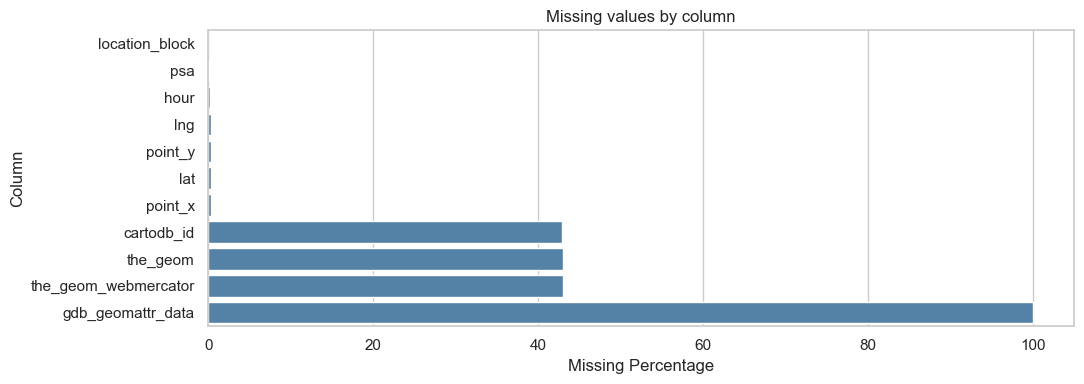

In [5]:
missing = check_missing_values(df)
display(missing)
missing_plot = missing.loc[missing["Missing Count"] > 0].sort_values("Missing Percentage")
if not missing_plot.empty:
    plt.figure(figsize=(11, max(4, 0.35 * len(missing_plot))))
    sns.barplot(data=missing_plot.reset_index(names="Column"), x="Missing Percentage", y="Column", color="steelblue")
    plt.title("Missing values by column")
    plt.tight_layout()
    plt.show()


### Duplicate records and duplicate incident keys

In [6]:
duplicate_summary = check_duplicates(df)
duplicate_rows = int(duplicate_summary["duplicate_count"])
duplicate_pct = duplicate_rows / len(df) * 100 if len(df) else 0.0
print(f"Exact duplicate rows: {duplicate_rows:,} ({duplicate_pct:.3f}%)")
if "dc_key" in df.columns:
    duplicate_keys = int(df["dc_key"].duplicated(keep=False).sum())
    repeated_key_values = int(df.loc[df["dc_key"].duplicated(keep=False), "dc_key"].nunique())
    print(f"Rows with repeated dc_key: {duplicate_keys:,}; repeated key values: {repeated_key_values:,}")


Exact duplicate rows: 0 (0.000%)
Rows with repeated dc_key: 167; repeated key values: 83


### Data types, date range, and value validation

In [7]:
for col in ["dispatch_date", "dispatch_date_time", "dispatch_time", "hour", "lat", "lng", "point_x", "point_y"]:
    if col in df.columns:
        print(f"{col}: {df[col].dtype}; non-null={df[col].notna().sum():,}; unique={df[col].nunique(dropna=True):,}")

date_col = "dispatch_date" if "dispatch_date" in analysis.columns else ("dispatch_date_time" if "dispatch_date_time" in analysis.columns else None)
if date_col:
    analysis["_eda_datetime"] = pd.to_datetime(analysis[date_col], errors="coerce", utc=True)
    nat_count = int(analysis["_eda_datetime"].isna().sum())
    print(f"Date source: {date_col}; values not parseable as dates (NaT): {nat_count:,}")
    print("Date range:", analysis["_eda_datetime"].min(), "to", analysis["_eda_datetime"].max())
else:
    analysis["_eda_datetime"] = pd.NaT
    print("No supported date column is present; date-based analyses will be skipped.")

if "hour" in df.columns:
    hour_num = pd.to_numeric(df["hour"], errors="coerce")
    invalid_hour = hour_num.notna() & ~hour_num.between(0, 23)
    print(f"Hour min={hour_num.min()}, max={hour_num.max()}, invalid non-null={int(invalid_hour.sum()):,}, missing/unparseable={int(hour_num.isna().sum()):,}")
if "lat" in df.columns and "lng" in df.columns:
    lat = pd.to_numeric(df["lat"], errors="coerce"); lng = pd.to_numeric(df["lng"], errors="coerce")
    invalid_lat = lat.notna() & ~lat.between(-90, 90)
    invalid_lng = lng.notna() & ~lng.between(-180, 180)
    print(f"Latitude invalid: {int(invalid_lat.sum()):,}; longitude invalid: {int(invalid_lng.sum()):,}; rows with either coordinate missing: {int((lat.isna() | lng.isna()).sum()):,}")


dispatch_date: object; non-null=736,033; unique=1,827


dispatch_date_time: object; non-null=736,033; unique=613,770
dispatch_time: object; non-null=736,033; unique=10,406
hour: float64; non-null=734,430; unique=24
lat: float64; non-null=733,059; unique=25,593
lng: float64; non-null=733,059; unique=25,593
point_x: float64; non-null=733,059; unique=25,586
point_y: float64; non-null=733,059; unique=25,588


Date source: dispatch_date; values not parseable as dates (NaT): 0
Date range: 2017-12-31 00:00:00+00:00 to 2022-12-31 00:00:00+00:00
Hour min=0.0, max=23.0, invalid non-null=0, missing/unparseable=1,603
Latitude invalid: 0; longitude invalid: 0; rows with either coordinate missing: 2,974


## 7. Temporal EDA

Temporal summaries use parsed incident dispatch dates and retain chronological ordering. Counts reflect records in the file; incomplete or invalid dates are excluded from date-derived summaries and are reported above.

,Incident Count,YoY Change (%)
year,,
2018,154589,NaN
2019,161448,4.44
2020,134411,-16.75
2021,134383,-0.02
2022,151152,12.48


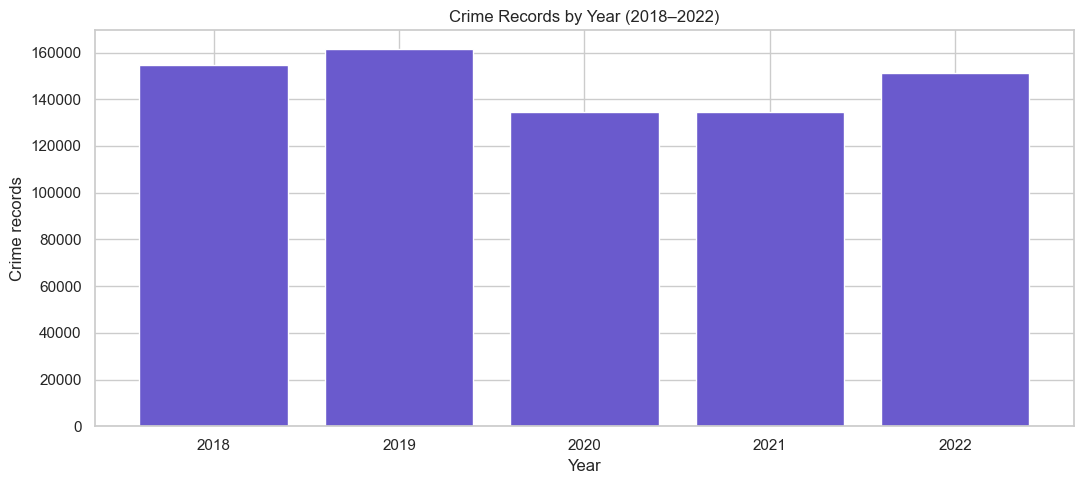

,Incident Count
month,
January,58294
February,53754
March,57387
April,58234
May,64739
June,63845
July,65035
August,65736
September,64585


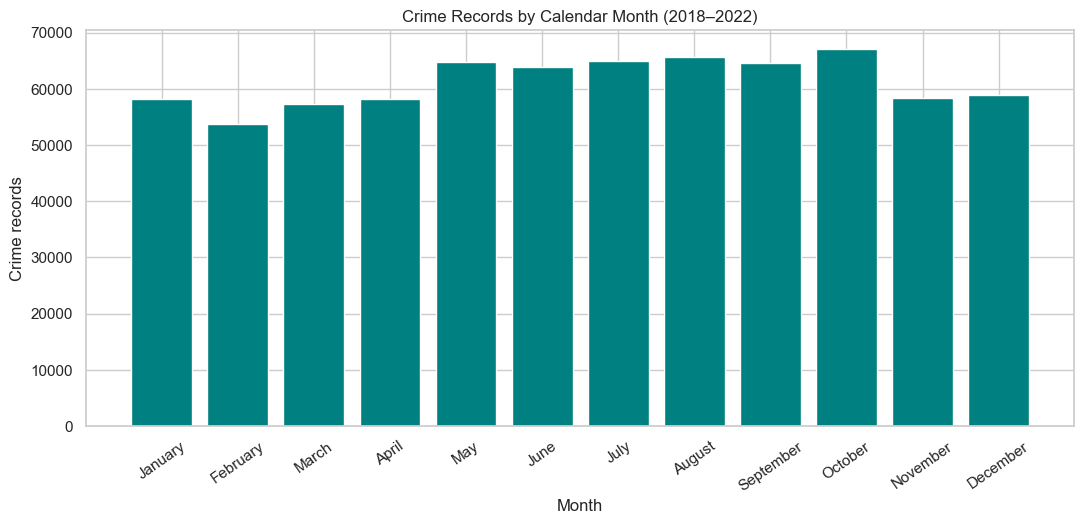

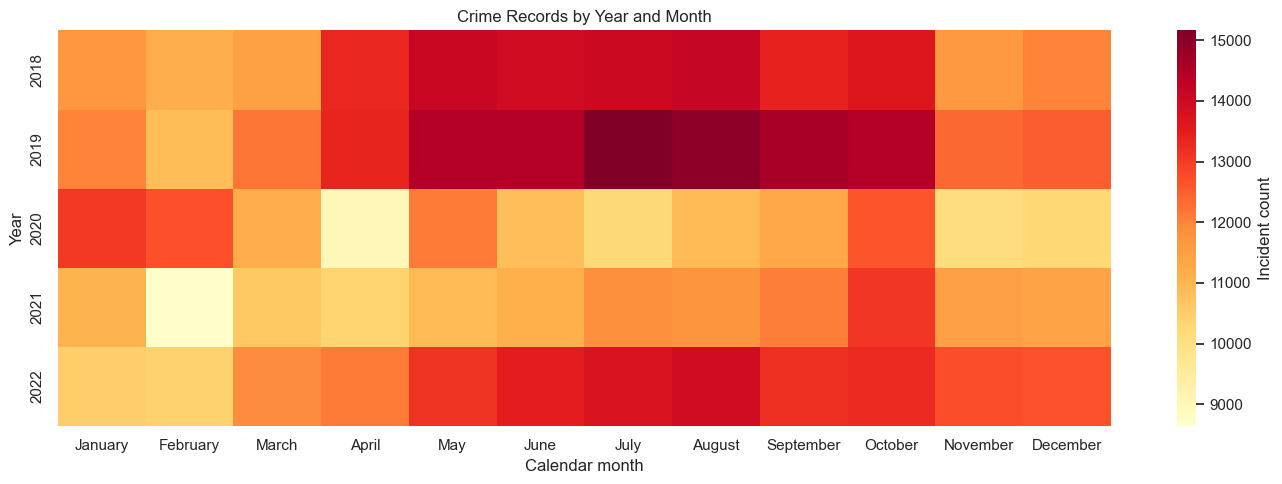

,Incident Count
weekday,
Monday,111790
Tuesday,113136
Wednesday,112212
Thursday,108648
Friday,106448
Saturday,94879
Sunday,88870


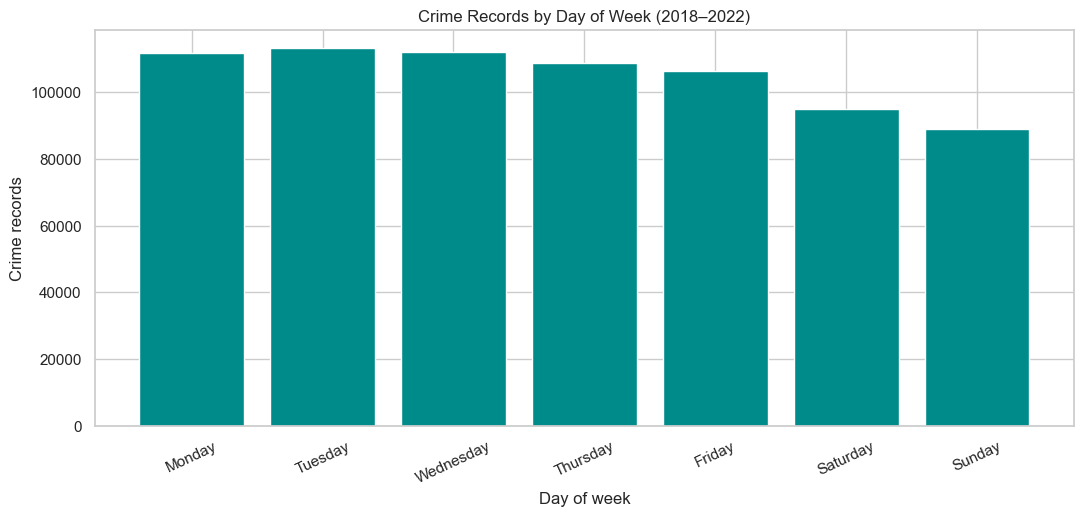

In [8]:
valid_dates = analysis.loc[analysis["_eda_datetime"].notna()].copy()
month_names = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
if not valid_dates.empty:
    valid_dates["year"] = valid_dates["_eda_datetime"].dt.year
    valid_dates["month_num"] = valid_dates["_eda_datetime"].dt.month
    valid_dates["month"] = pd.Categorical(valid_dates["_eda_datetime"].dt.month_name(), categories=month_names, ordered=True)
    valid_dates["weekday"] = pd.Categorical(valid_dates["_eda_datetime"].dt.day_name(), categories=weekday_names, ordered=True)
    # The combined file contains 50 records dated 2017. The requested temporal charts
    # describe the 2018–2022 study period; the 2017 records remain in df and audits.
    analysis_period = valid_dates.loc[valid_dates["year"].between(2018, 2022)].copy()
    yearly = analysis_period.groupby("year", observed=False).size().reindex(range(2018, 2023), fill_value=0).rename("Incident Count").to_frame()
    yearly["YoY Change (%)"] = yearly["Incident Count"].pct_change().mul(100).round(2)
    display(yearly)
    fig, ax = plot_ordered_counts(yearly["Incident Count"], "Crime Records by Year (2018–2022)", xlabel="Year", ylabel="Crime records", kind="bar", color="slateblue")
    ax.tick_params(axis="x", rotation=0)
    plt.show()

    monthly = analysis_period.groupby("month", observed=False).size().rename("Incident Count").to_frame()
    display(monthly)
    fig, ax = plot_ordered_counts(monthly["Incident Count"], "Crime Records by Calendar Month (2018–2022)", xlabel="Month", ylabel="Crime records", kind="bar", color="teal")
    ax.tick_params(axis="x", rotation=35)
    plt.show()

    year_month = analysis_period.pivot_table(index="year", columns="month_num", values="_eda_datetime", aggfunc="count", observed=False).reindex(index=range(2018, 2023), columns=range(1, 13), fill_value=0)
    year_month.columns = month_names
    fig, ax = plot_temporal_heatmap(year_month, title="Crime Records by Year and Month", xlabel="Calendar month", ylabel="Year", figsize=(14, 5), cmap="YlOrRd")
    plt.show()

    weekday = analysis_period.groupby("weekday", observed=False).size().rename("Incident Count").to_frame()
    display(weekday)
    fig, ax = plot_ordered_counts(weekday["Incident Count"], "Crime Records by Day of Week (2018–2022)", xlabel="Day of week", ylabel="Crime records", kind="bar", color="darkcyan")
    ax.tick_params(axis="x", rotation=25)
    plt.show()
else:
    analysis_period = valid_dates.copy()
    yearly = pd.DataFrame(columns=["Incident Count", "YoY Change (%)"]); monthly = pd.DataFrame(); weekday = pd.DataFrame(); year_month = pd.DataFrame()
    print("No valid dates available; temporal analyses skipped.")


**Observation:** Within 2018–2022, 2019 has the most records (161,448); October is the highest-count month (67,094), and Tuesday is the highest-count weekday (113,136). The dataset also contains 50 records dated 2017; these remain in the data and audit tables but are outside the requested temporal chart period.

,Incident Count
Hour,
0,23856
1,18439
2,14233
3,10874
4,8380
5,7375
6,6845
7,14584
8,30236


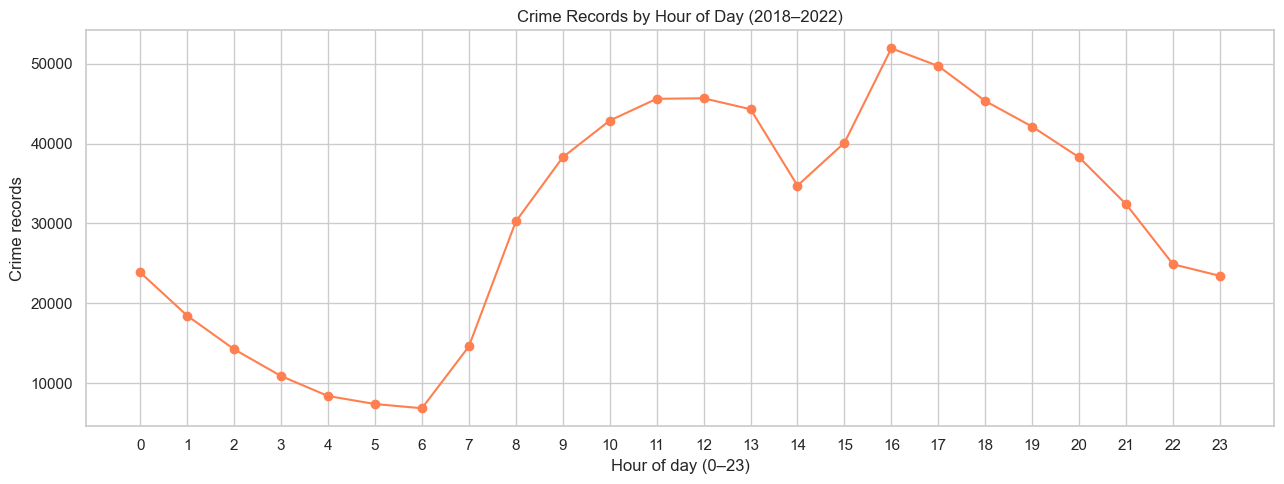

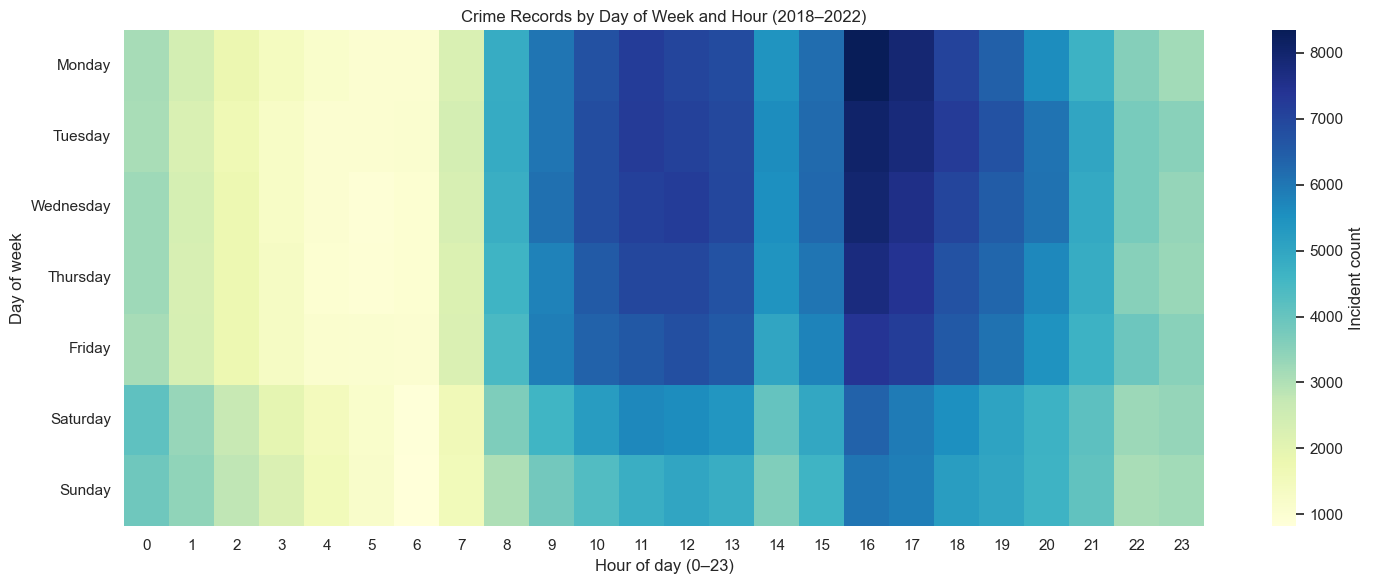

In [9]:
hour_values = None
if "hour" in analysis.columns:
    hour_values = pd.to_numeric(analysis["hour"], errors="coerce")
elif "dispatch_date_time" in analysis.columns:
    hour_values = pd.to_datetime(analysis["dispatch_date_time"], errors="coerce", utc=True).dt.hour
if hour_values is not None:
    period_hours = hour_values.loc[analysis_period.index]
    hourly = period_hours[period_hours.between(0, 23)].astype(int).value_counts().reindex(range(24), fill_value=0).sort_index().rename("Incident Count").to_frame()
    hourly.index.name = "Hour"
    display(hourly)
    fig, ax = plot_ordered_counts(hourly["Incident Count"], "Crime Records by Hour of Day (2018–2022)", xlabel="Hour of day (0–23)", ylabel="Crime records", kind="line", figsize=(13, 5), color="coral")
    ax.set_xticks(range(24))
    plt.show()
else:
    hourly = pd.DataFrame(); print("No hour or dispatch datetime field; hourly analysis skipped.")

if not analysis_period.empty and hour_values is not None:
    temp = analysis_period.copy()
    temp["hour_value"] = pd.to_numeric(hour_values.loc[temp.index], errors="coerce")
    day_hour = temp.pivot_table(index="weekday", columns="hour_value", values="_eda_datetime", aggfunc="count", observed=False).reindex(index=weekday_names, columns=range(24), fill_value=0)
    fig, ax = plot_temporal_heatmap(day_hour, title="Crime Records by Day of Week and Hour (2018–2022)", xlabel="Hour of day (0–23)", ylabel="Day of week", figsize=(15, 6))
    plt.show()


**Observation:** The hourly distribution peaks at 16:00 (51,922 records). The day-by-hour heatmap has its largest cell on Monday at 16:00 (8,341 records). Both charts count valid reported time values only.

## 8. Crime Type EDA

Crime type labels are preserved as recorded; categories are not merged. Frequency percentages use non-missing crime-type records as the denominator.

,Incident Count,Percentage (%)
Crime Type,,
Thefts,127055,17.26
Other Assaults,119583,16.25
All Other Offenses,95265,12.94
Vandalism/Criminal Mischief,71977,9.78
Theft from Vehicle,67615,9.19
Fraud,46603,6.33
Narcotic / Drug Law Violations,33032,4.49
Aggravated Assault No Firearm,26504,3.60
Motor Vehicle Theft,25402,3.45


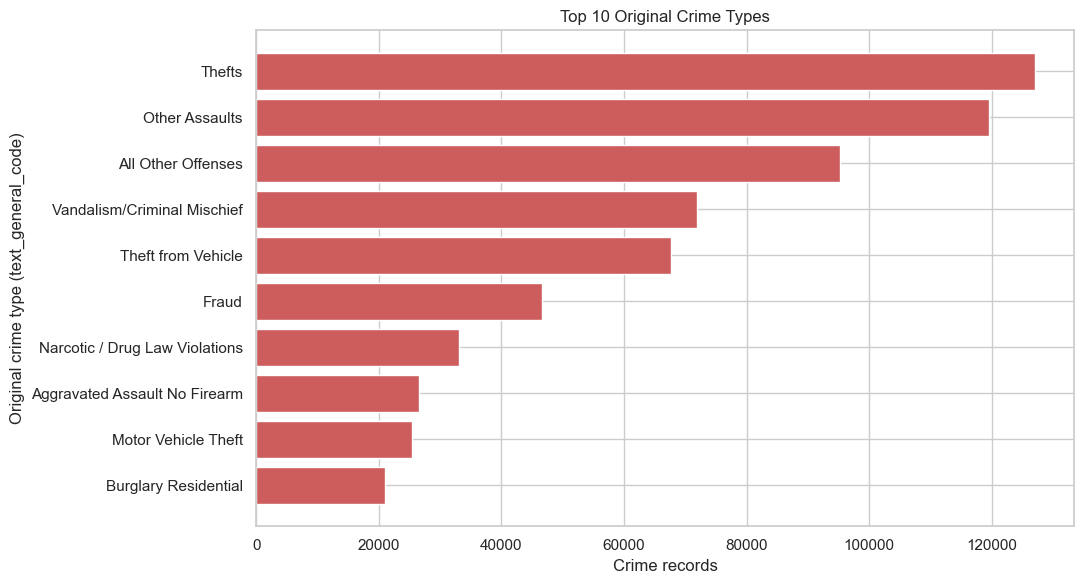

text_general_code,Thefts,Other Assaults,All Other Offenses,Vandalism/Criminal Mischief,Theft from Vehicle,Fraud,Narcotic / Drug Law Violations,Aggravated Assault No Firearm,Motor Vehicle Theft,Burglary Residential
year,,,,,,,,,,
2018,23369,23771,25651,14694,13592,12428,9428,5380,1765,5089
2019,25099,24603,30833,14717,13188,9779,10384,5617,1796,4780
2020,20914,21918,15978,14527,12819,8712,6447,5483,2539,3639
2021,24567,23934,10845,13666,12472,8757,3845,5104,7487,3714
2022,33100,25351,11946,14368,15543,6922,2927,4920,11815,3721


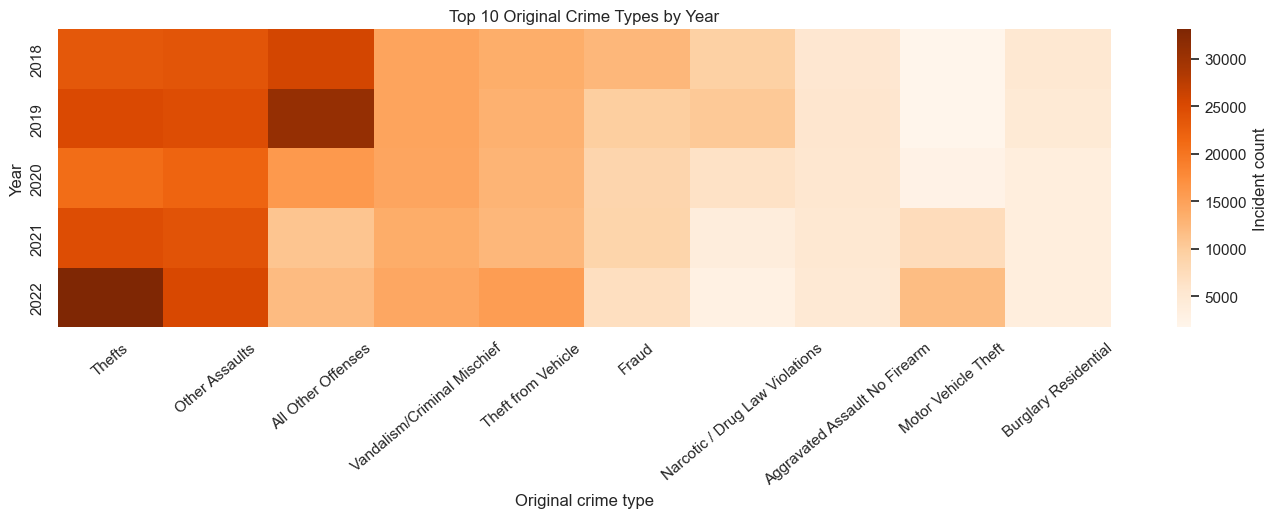

In [10]:
crime_col = "text_general_code" if "text_general_code" in df.columns else None
if crime_col:
    crime_counts = df[crime_col].value_counts(dropna=True)
    crime_summary = pd.DataFrame({"Incident Count": crime_counts, "Percentage (%)": (crime_counts / crime_counts.sum() * 100).round(2)})
    crime_summary.index.name = "Crime Type"
    display(crime_summary)
    top_n = 10
    top_crimes = crime_summary.head(top_n)
    top_crime_counts = top_crimes["Incident Count"].sort_values(ascending=True)
    fig, ax = plot_ordered_counts(top_crime_counts, f"Top {top_n} Original Crime Types", xlabel="Crime records", ylabel="Original crime type (text_general_code)", kind="barh", figsize=(11, 6), color="indianred")
    plt.show()
    crime_year = pd.crosstab(analysis_period["year"], df.loc[analysis_period.index, crime_col]) if not analysis_period.empty else pd.DataFrame()
    top_names = list(top_crimes.index)
    if not crime_year.empty:
        crime_year = crime_year.reindex(index=range(2018, 2023), columns=top_names, fill_value=0)
        display(crime_year)
        fig, ax = plot_temporal_heatmap(crime_year, title=f"Top {top_n} Original Crime Types by Year", xlabel="Original crime type", ylabel="Year", figsize=(14, 6), cmap="Oranges")
        ax.tick_params(axis="x", labelrotation=40)
        plt.show()
else:
    crime_summary = pd.DataFrame(); top_crimes = crime_summary; crime_year = pd.DataFrame()
    print("text_general_code is absent; crime-type analysis skipped.")


**Observation:** The top-N chart uses the original `text_general_code` labels; Thefts is the most frequent overall (127,055 records). In the year heatmap, All Other Offenses leads in 2018 and 2019, Other Assaults leads in 2020, and Thefts leads in 2021 and 2022.

## 9. Spatial / Location EDA

District and PSA count tables describe recorded workload counts only. Higher counts do not establish that an area is more dangerous. Coordinate plots show observed valid points without external basemaps or inferred boundaries.

,Incident Count
Police District,
24,54050
15,52924
22,51671
19,48433
35,46575
25,43471
14,41746
12,41540
39,41255


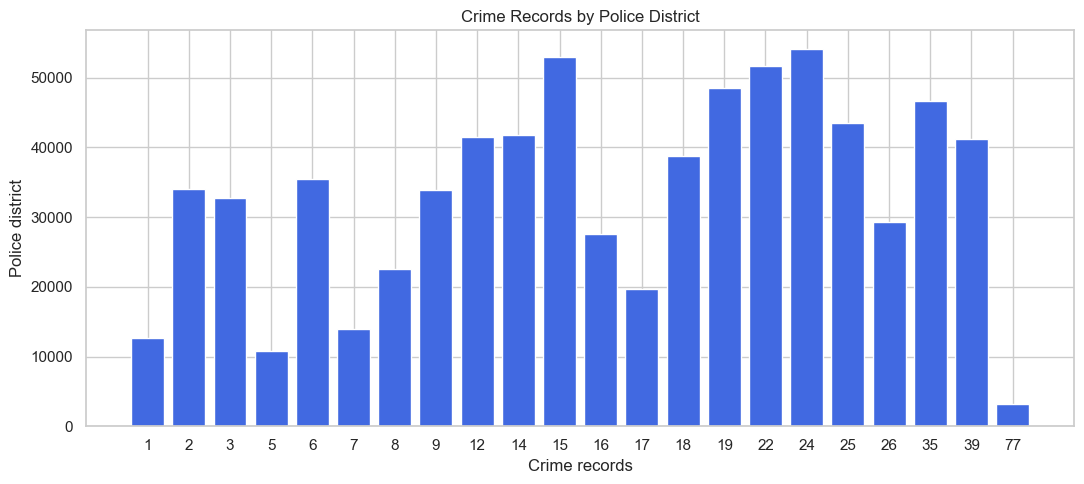

Unique non-missing PSAs: 5; missing PSA records shown in chart: 370


,Incident Count
PSA (missing shown separately),
2,258747
1,228202
3,209075
4,36432
A,3207
Missing PSA,370


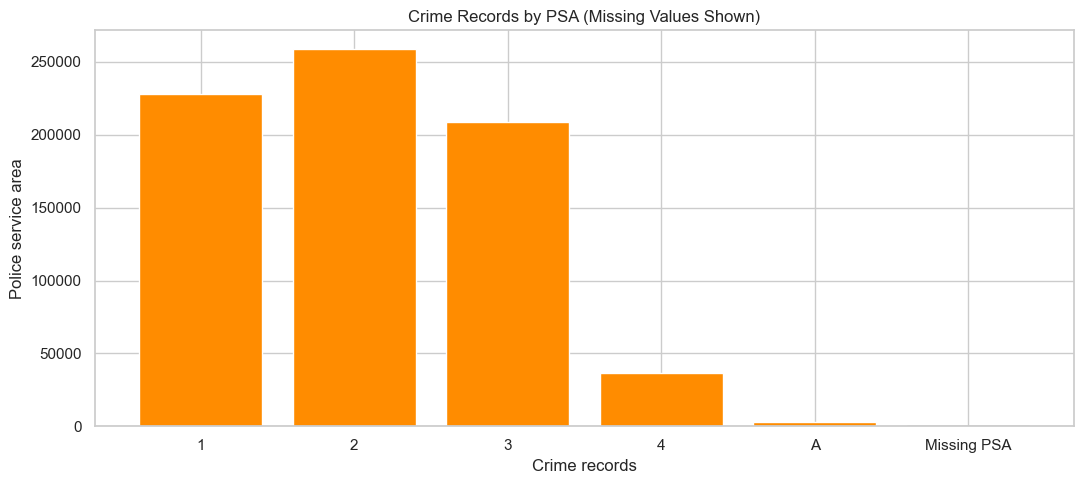

Hexbin uses all 733,059 valid coordinate pairs; 2,974 rows with missing, nonnumeric, non-finite, or out-of-range coordinates are excluded. No coordinates are imputed.


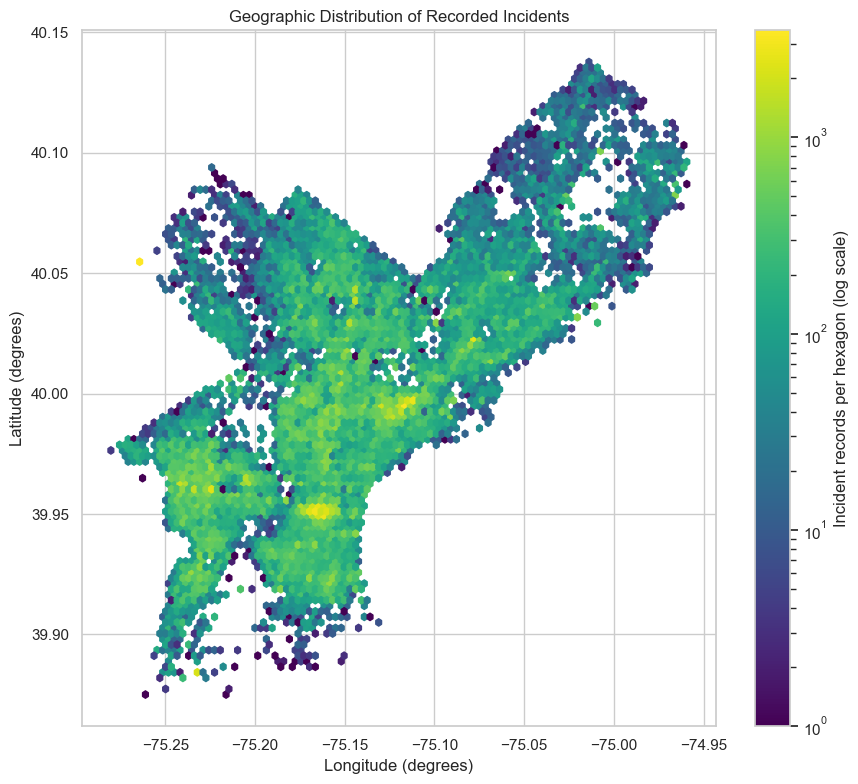

point_x: non-null=733,059; min=-75.28030675; median=-75.15867749; max=-74.9593644
point_y: non-null=733,059; min=39.87503164; median=39.9911351; max=40.1376938


In [11]:
if "dc_dist" in df.columns:
    district_counts = df["dc_dist"].value_counts(dropna=True)
    district_summary = district_counts.rename("Incident Count").to_frame(); district_summary.index.name = "Police District"
    display(district_summary)
    ordered_district_counts = district_counts.sort_index(key=lambda x: pd.to_numeric(x, errors="coerce"))
    fig, ax = plot_ordered_counts(ordered_district_counts, "Crime Records by Police District", xlabel="Crime records", ylabel="Police district", kind="bar", color="royalblue")
    ax.tick_params(axis="x", rotation=0)
    plt.show()
else:
    district_counts = pd.Series(dtype=int); district_summary = pd.DataFrame(); print("dc_dist is absent; district analysis skipped.")

if "psa" in df.columns:
    # Keep every PSA and add a named missing category instead of dropping 370 rows.
    psa_counts = df["psa"].astype("string").fillna("Missing PSA").value_counts()
    psa_summary = psa_counts.rename("Incident Count").to_frame(); psa_summary.index.name = "PSA (missing shown separately)"
    print(f"Unique non-missing PSAs: {df['psa'].nunique(dropna=True):,}; missing PSA records shown in chart: {int(df['psa'].isna().sum()):,}")
    display(psa_summary)
    psa_order = sorted([v for v in psa_counts.index if v != "Missing PSA"], key=lambda x: (not str(x).isdigit(), int(x) if str(x).isdigit() else str(x)))
    if "Missing PSA" in psa_counts.index:
        psa_order.append("Missing PSA")
    psa_counts = psa_counts.reindex(psa_order)
    fig, ax = plot_ordered_counts(psa_counts, "Crime Records by PSA (Missing Values Shown)", xlabel="Crime records", ylabel="Police service area", kind="bar", color="darkorange")
    if "Missing PSA" in psa_order:
        ax.patches[-1].set_color("gray")
    ax.tick_params(axis="x", rotation=0)
    plt.show()
else:
    psa_counts = pd.Series(dtype=int); print("psa is absent; PSA analysis skipped.")

if "lat" in df.columns and "lng" in df.columns:
    fig, ax, valid_coordinate_rows, excluded_coordinate_rows = plot_geographic_hexbin(df, latitude="lat", longitude="lng", gridsize=100)
    print(f"Hexbin uses all {valid_coordinate_rows:,} valid coordinate pairs; {excluded_coordinate_rows:,} rows with missing, nonnumeric, non-finite, or out-of-range coordinates are excluded. No coordinates are imputed.")
    plt.show()
else:
    print("lat and/or lng absent; coordinate density plot skipped.")

for col in ["point_x", "point_y"]:
    if col in df.columns:
        numeric = pd.to_numeric(df[col], errors="coerce")
        print(f"{col}: non-null={numeric.notna().sum():,}; min={numeric.min()}; median={numeric.median()}; max={numeric.max()}")


**Observation:** District 24 has the largest recorded count (54,050). PSA 2 has the largest count (258,747); the graph separately displays 370 records with missing PSA rather than omitting them. The hexbin aggregates all 733,059 valid coordinate pairs and excludes 2,974 invalid or missing pairs without imputing locations.

## 10. Cross-Dimensional EDA

The following frequency tables compare recorded counts across dimensions. Heatmap values are counts; an association in these tables does not imply causation.

dc_dist,1,12,14,15,16,17,18,19,2,22,24,25,26,3,35,39,5,6,7,77,8,9
year,,,,,,,,,,,,,,,,,,,,,,
2018,2503,8070,8821,11220,5790,4479,8562,12237,6645,10457,12121,8866,5527,6615,9462,8978,2213,7218,2615,646,4258,7286
2019,2566,8384,8639,11002,6786,4655,9127,10778,6629,10962,13580,9524,5709,7169,10821,9023,2263,8509,2505,672,4322,7823
2020,2016,8357,8172,9449,5119,3489,7061,8375,5990,9232,9963,8500,5382,5970,9050,7422,1813,5934,2436,499,4198,5984
2021,2389,8130,7688,9910,4737,3280,6390,8387,6690,10093,9222,7926,5790,5815,8219,7808,2084,6114,2788,622,4368,5933
2022,3215,8596,8422,11342,5166,3717,7575,8653,8027,10927,9162,8650,6892,7087,9014,8024,2476,7643,3547,770,5429,6818


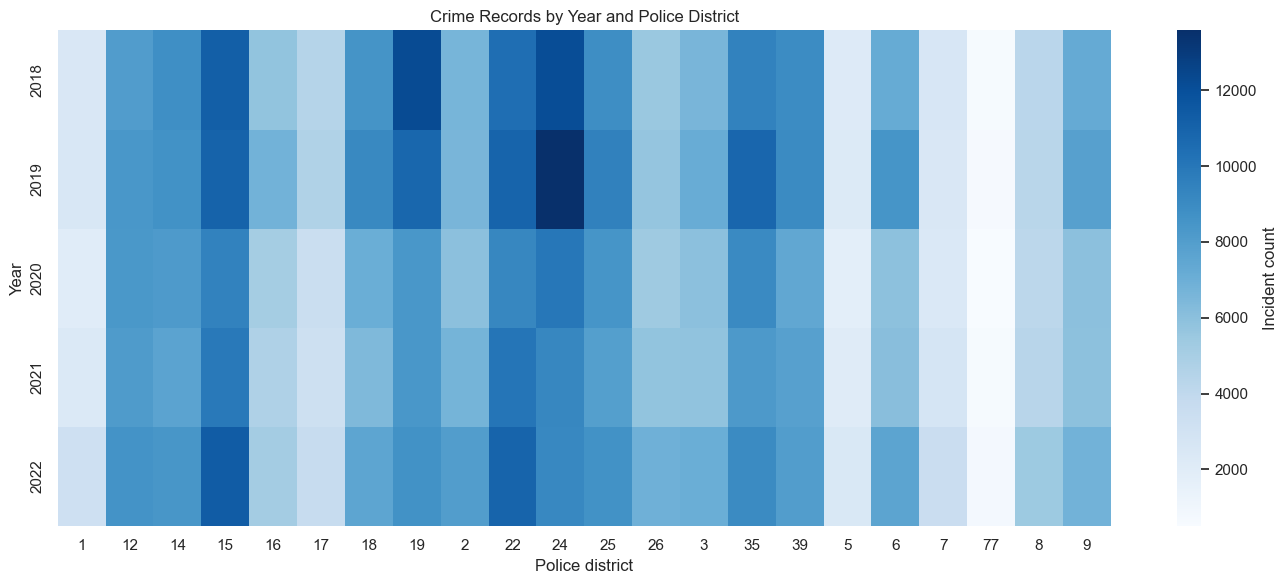

Crime Type,Thefts,Other Assaults,All Other Offenses,Vandalism/Criminal Mischief,Theft from Vehicle,Fraud,Narcotic / Drug Law Violations,Aggravated Assault No Firearm,Motor Vehicle Theft,Burglary Residential
dc_dist,,,,,,,,,,
24,6849,6714,7584,3645,3347,2392,8770,2159,1647,890
15,8526,9043,5493,6300,5161,3556,1355,1883,2582,1370
22,7198,9914,4725,6250,4861,2651,1665,2208,1962,2511
19,6053,9825,9141,4848,2561,3222,2224,1799,1457,1308
35,5934,8781,6305,5172,3313,2726,1976,1916,1770,1271
25,4315,7727,4487,4227,3144,1809,3602,2407,1635,932
14,5721,8353,4957,4687,3573,3716,1644,1364,1345,1158
12,4613,7303,6440,4533,3224,2311,1997,1655,2069,1287
39,5035,8782,4919,4228,3263,2608,1663,1746,1381,1425


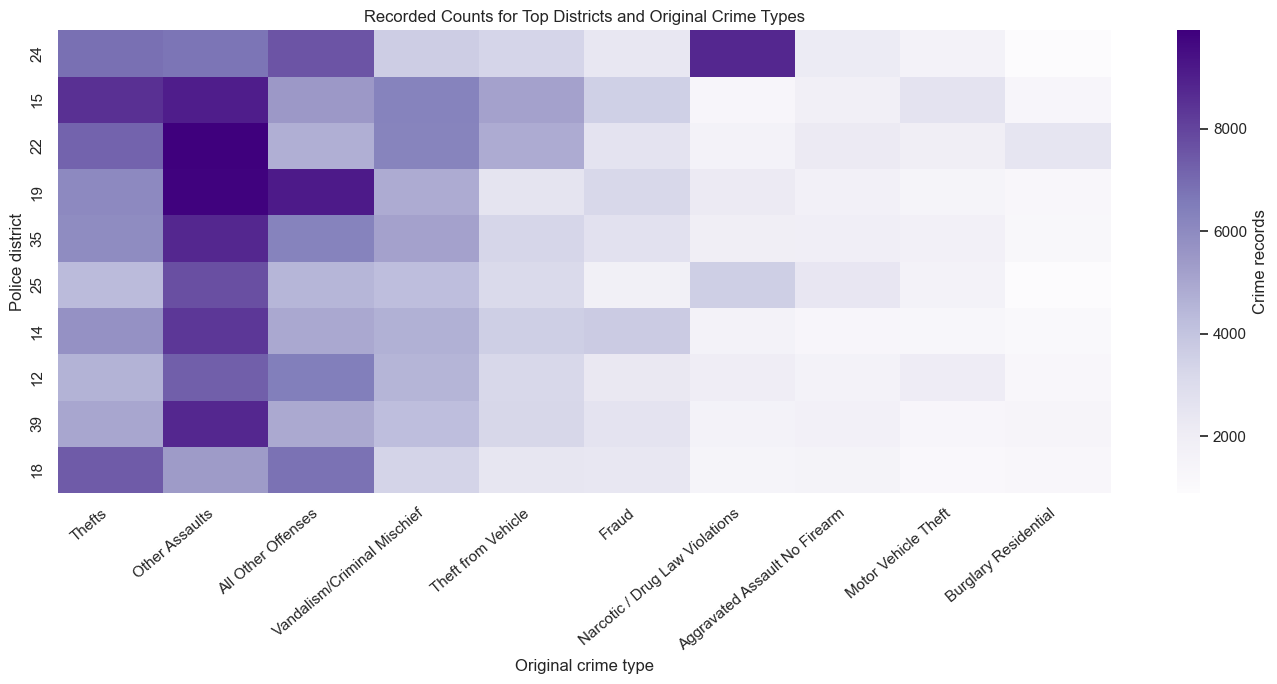

In [12]:
if not analysis_period.empty and "dc_dist" in df.columns:
    year_district = pd.crosstab(analysis_period["year"], df.loc[analysis_period.index, "dc_dist"])
    year_district = year_district.reindex(index=range(2018, 2023), columns=sorted(year_district.columns, key=lambda x: str(x)))
    display(year_district)
    fig, ax = plot_temporal_heatmap(year_district, title="Crime Records by Year and Police District", xlabel="Police district", ylabel="Year", figsize=(14, 6), cmap="Blues")
    plt.show()

if crime_col and "dc_dist" in df.columns and len(crime_summary):
    top_districts = district_counts.sort_values(ascending=False).head(10).index
    top_types = crime_summary.head(10).index
    district_crime = pd.crosstab(df.loc[df["dc_dist"].isin(top_districts), "dc_dist"], df.loc[df["dc_dist"].isin(top_districts), crime_col])
    district_crime = district_crime.reindex(index=top_districts, columns=top_types, fill_value=0)
    display(district_crime)
    plt.figure(figsize=(14, 7)); sns.heatmap(district_crime, cmap="Purples", cbar_kws={"label": "Crime records"})
    plt.title("Recorded Counts for Top Districts and Original Crime Types"); plt.xlabel("Original crime type"); plt.ylabel("Police district"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()


**Observation:** The cross-tabulations show that recorded counts vary across year–district and district–crime-type combinations. They are counts, not population-adjusted rates.

## 11. Numerical Variable Analysis

Only potentially interpretable measurement fields are considered. Identifier-like fields (`objectid`, `dc_key`, and row identifiers) are excluded. Correlation measures statistical association and does not establish causation.

,count,mean,std,min,25%,50%,75%,max
Column,,,,,,,,
hour,734430.0,13.405809,5.925255,0.000000,10.000000,14.000000,18.000000,23.000000
lat,733059.0,39.992390,0.044775,39.875032,39.956938,39.991135,40.027605,40.137694
lng,733059.0,-75.153278,0.059011,-75.280307,-75.188780,-75.158677,-75.122363,-74.959364
point_x,733059.0,-75.153278,0.059011,-75.280307,-75.188780,-75.158677,-75.122363,-74.959364
point_y,733059.0,39.992390,0.044775,39.875032,39.956938,39.991135,40.027605,40.137694


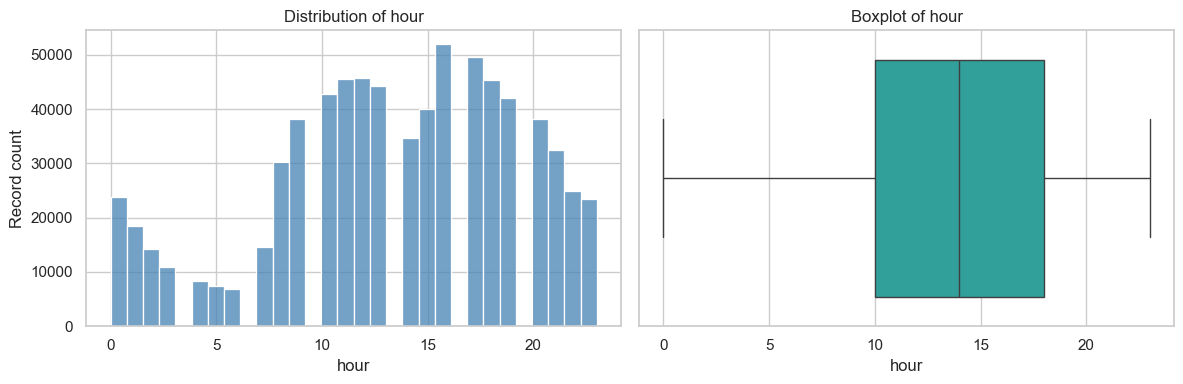

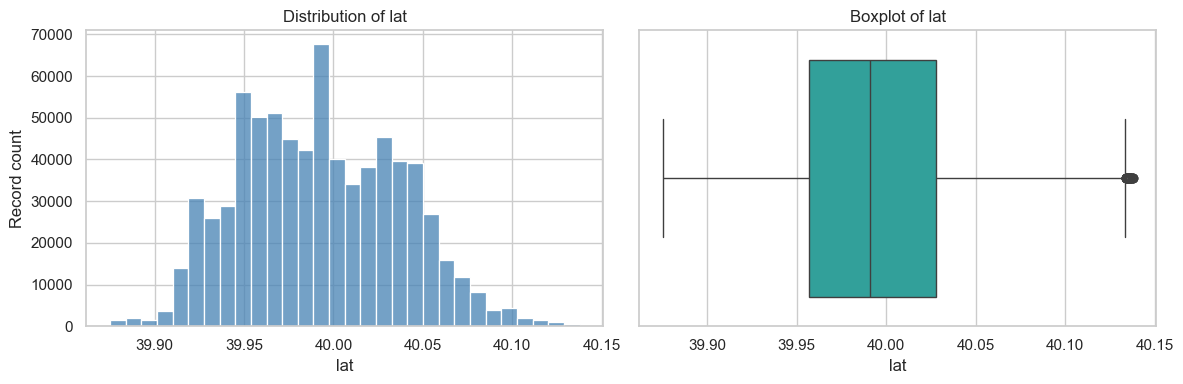

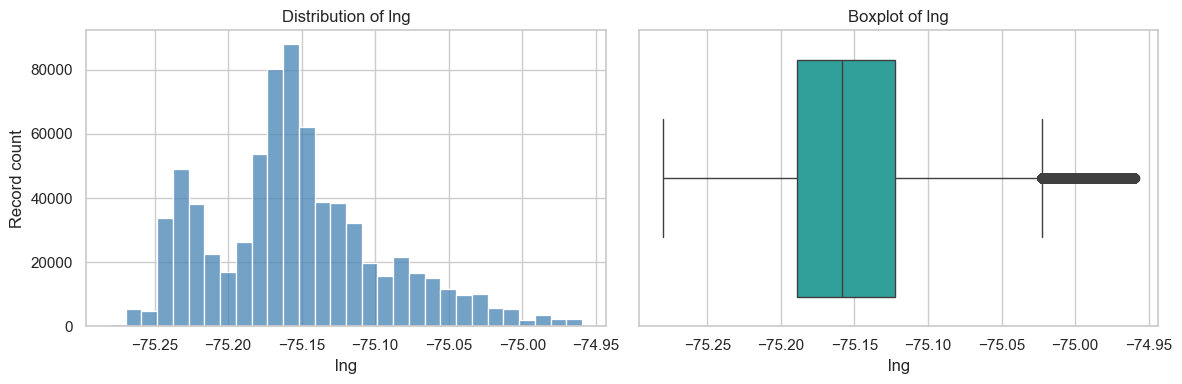

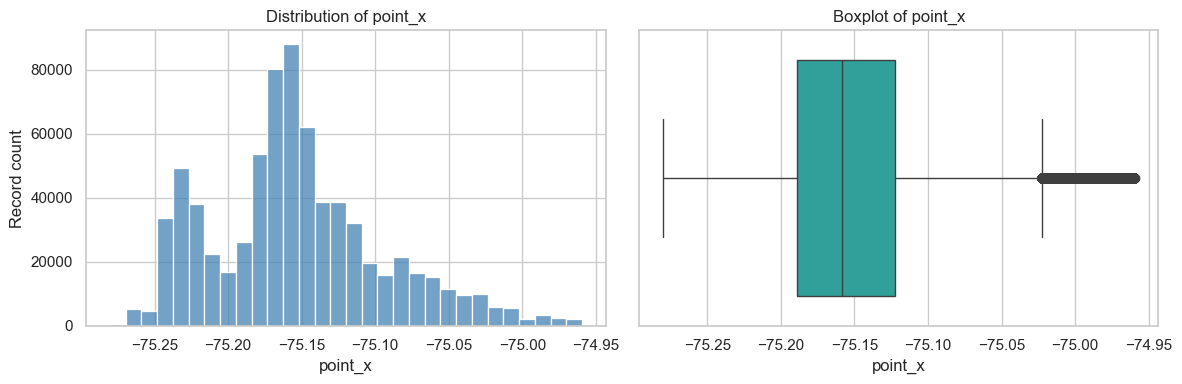

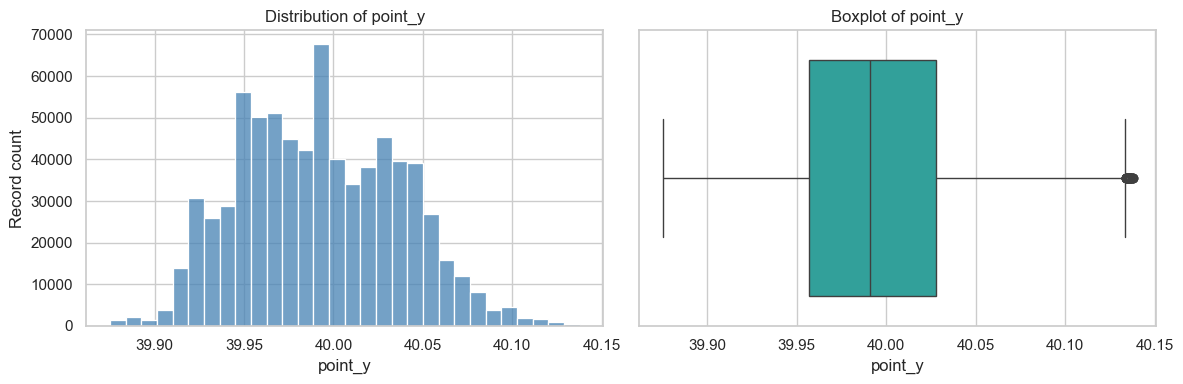

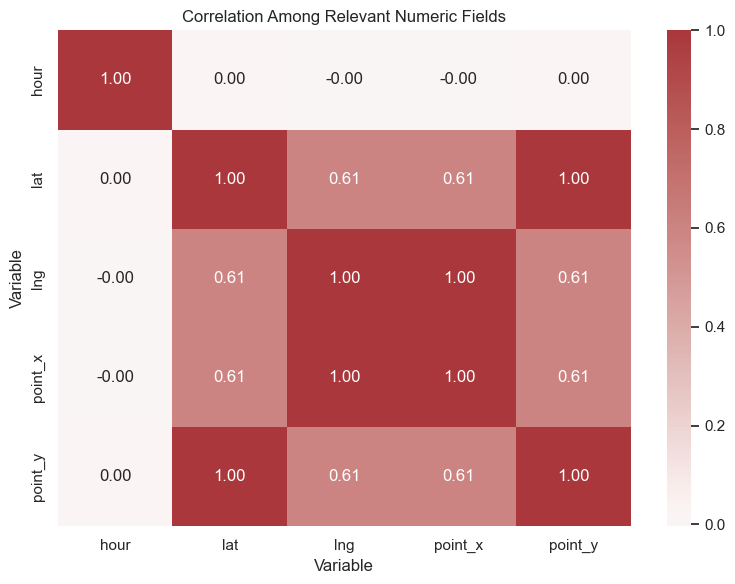

In [13]:
numeric_candidates = ["hour", "lat", "lng", "point_x", "point_y"]
numeric_cols = [c for c in numeric_candidates if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if numeric_cols:
    numeric_summary = df[numeric_cols].describe().T
    display(numeric_summary)
    for col in numeric_cols:
        series = df[col].dropna()
        if series.empty: continue
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        sns.histplot(series, bins=30, ax=axes[0], color="steelblue")
        axes[0].set(title=f"Distribution of {col}", xlabel=col, ylabel="Record count")
        sns.boxplot(x=series, ax=axes[1], color="lightseagreen")
        axes[1].set(title=f"Boxplot of {col}", xlabel=col, ylabel="")
        plt.tight_layout(); plt.show()
    if len(numeric_cols) > 1:
        fig, ax = plot_correlation_heatmap(df[numeric_cols], title="Correlation Among Relevant Numeric Fields", figsize=(8, 6))
        plt.show()
else:
    numeric_summary = pd.DataFrame(); print("No available numeric analysis variables among the selected fields.")


**Observation:** The correlation heatmap shows the supplied numeric fields only. Latitude and point_y are perfectly correlated in this file, as are longitude and point_x; these coordinate pairs are alternate representations of location. Hour has near-zero linear correlation with the coordinate fields.

## 12. Key EDA Observations

The statements below are generated from the summaries above. They describe recorded counts and should be interpreted in light of missing or invalid values noted earlier.

In [14]:
observations = []
if not yearly.empty and yearly["Incident Count"].notna().any():
    y = yearly["Incident Count"].idxmax(); observations.append(f"The year with the highest recorded number of incidents was {y} ({int(yearly.loc[y, 'Incident Count']):,}).")
if not monthly.empty and monthly["Incident Count"].notna().any():
    m = monthly["Incident Count"].idxmax(); observations.append(f"The month with the highest recorded incident count was {m} ({int(monthly.loc[m, 'Incident Count']):,}).")
if not weekday.empty and weekday["Incident Count"].notna().any():
    w = weekday["Incident Count"].idxmax(); observations.append(f"The weekday with the highest recorded incident count was {w} ({int(weekday.loc[w, 'Incident Count']):,}).")
if not hourly.empty and hourly["Incident Count"].notna().any():
    h = hourly["Incident Count"].idxmax(); observations.append(f"The hour with the highest recorded incident count was {h} ({int(hourly.loc[h, 'Incident Count']):,}).")
if len(crime_summary):
    c = crime_summary.index[0]; observations.append(f"The most frequently recorded crime type was {c} ({int(crime_summary.iloc[0]['Incident Count']):,}).")
if len(district_counts):
    d = district_counts.index[0]; observations.append(f"The district with the highest recorded incident count was {d} ({int(district_counts.iloc[0]):,}).")
if not observations: observations.append("Available columns or valid observations were insufficient to generate count-based observations.")
for item in observations: print("• " + item)


• The year with the highest recorded number of incidents was 2019 (161,448).
• The month with the highest recorded incident count was October (67,094).
• The weekday with the highest recorded incident count was Tuesday (113,136).
• The hour with the highest recorded incident count was 16 (51,922).
• The most frequently recorded crime type was Thefts (127,055).
• The district with the highest recorded incident count was 24 (54,050).


### EDA Summary Table

All values in this table are calculated from the loaded data and available fields.

In [15]:
summary_rows = [("Total incidents", f"{len(df):,}")]
if analysis["_eda_datetime"].notna().any():
    summary_rows.append(("Date range", f"{analysis['_eda_datetime'].min().date()} to {analysis['_eda_datetime'].max().date()}"))
if crime_col: summary_rows.append(("Number of crime types", f"{df[crime_col].nunique(dropna=True):,}"))
if "dc_dist" in df: summary_rows.append(("Number of police districts", f"{df['dc_dist'].nunique(dropna=True):,}"))
if "psa" in df: summary_rows.append(("Number of PSAs", f"{df['psa'].nunique(dropna=True):,}"))
if not yearly.empty:
    i = yearly["Incident Count"].idxmax(); summary_rows.append(("Highest incident-count year", f"{i} ({int(yearly.loc[i, 'Incident Count']):,})"))
if not monthly.empty:
    i = monthly["Incident Count"].idxmax(); summary_rows.append(("Highest incident-count month", f"{i} ({int(monthly.loc[i, 'Incident Count']):,})"))
if not weekday.empty:
    i = weekday["Incident Count"].idxmax(); summary_rows.append(("Highest incident-count weekday", f"{i} ({int(weekday.loc[i, 'Incident Count']):,})"))
if not hourly.empty:
    i = hourly["Incident Count"].idxmax(); summary_rows.append(("Highest incident-count hour", f"{i} ({int(hourly.loc[i, 'Incident Count']):,})"))
if len(crime_summary): summary_rows.append(("Most frequent crime type", str(crime_summary.index[0])))
if len(district_counts): summary_rows.append(("Highest-count district", str(district_counts.index[0])))
summary_rows.extend([("Exact duplicate rows", f"{duplicate_rows:,} ({duplicate_pct:.3f}%)"), ("Total missing cells", f"{int(df.isna().sum().sum()):,}")])
eda_summary = pd.DataFrame(summary_rows, columns=["Metric", "Result"])
display(eda_summary)


,Metric,Result
0,Total incidents,"736,033"
1,Date range,2017-12-31 to 2022-12-31
2,Number of crime types,32
3,Number of police districts,22
4,Number of PSAs,5
5,Highest incident-count year,"2019 (161,448)"
6,Highest incident-count month,"October (67,094)"
7,Highest incident-count weekday,"Tuesday (113,136)"
8,Highest incident-count hour,"16 (51,922)"
9,Most frequent crime type,Thefts


## Dataset and EDA Audit

This audit verifies source-year contributions, date boundaries, missingness patterns, repeated identifiers, category counts, coordinate validity, and hour values. No rows are removed and no values are imputed. The source CSV remains unchanged.

### Source-year contributions

Counts and date limits are calculated from `source_year` and the parsed `dispatch_date`. The total row check is calculated from the data rather than assumed.

In [16]:
if "source_year" in df.columns:
    audit_dates = pd.to_datetime(df["dispatch_date"], errors="coerce") if "dispatch_date" in df.columns else pd.Series(pd.NaT, index=df.index)
    year_audit = pd.DataFrame({"source_year": df["source_year"], "dispatch_date": audit_dates}).groupby("source_year", dropna=False).agg(
        row_count=("source_year", "size"), minimum_dispatch_date=("dispatch_date", "min"), maximum_dispatch_date=("dispatch_date", "max")
    ).reset_index()
    display(year_audit)
    requested_years = year_audit.loc[year_audit["source_year"].isin([2018, 2019, 2020, 2021, 2022]), "row_count"].sum()
    print(f"Total dataset rows: {len(df):,}")
    print(f"Sum of rows for source_year 2018–2022: {int(requested_years):,}")
    print(f"Row totals reconcile: {int(requested_years) == len(df)}")
else:
    year_audit = pd.DataFrame(); print("source_year is absent; contribution audit unavailable.")

,source_year,row_count,minimum_dispatch_date,maximum_dispatch_date
0,2018,154590,2017-12-31,2018-12-31
1,2019,161442,2018-12-31,2019-12-31
2,2020,134401,2019-12-31,2020-12-31
3,2021,134403,2020-12-31,2021-12-31
4,2022,151197,2021-12-31,2022-12-31


Total dataset rows: 736,033
Sum of rows for source_year 2018–2022: 736,033
Row totals reconcile: True


### Date boundary records

Records before 2018 are displayed for review, not filtered. The `source_year` field provides evidence about the year bucket in the combined dataset, while the dispatch date records the incident date. The audit shows these 50 records are assigned to source_year 2018, have dispatch_date 2017-12-31, and have dispatch_date_time on 2018-01-01. This is consistent with a local-date versus UTC timestamp boundary, but the columns alone do not prove provenance or the project's scope rule. The records are retained and flagged for source validation if strict calendar-year scope is required.

In [17]:
if "dispatch_date" in df.columns:
    parsed_date = pd.to_datetime(df["dispatch_date"], errors="coerce")
    before_2018 = parsed_date < pd.Timestamp("2018-01-01")
    early_columns = [c for c in ["source_year", "objectid", "dc_key", "dispatch_date", "dispatch_date_time", "dispatch_time", "text_general_code", "dc_dist", "psa", "lat", "lng"] if c in df.columns]
    print(f"Records before 2018-01-01: {int(before_2018.sum()):,}")
    display(df.loc[before_2018, early_columns])
    maximum_date = parsed_date.max()
    print(f"Maximum dispatch_date: {maximum_date}")
    print(f"Records on maximum date: {int((parsed_date == maximum_date).sum()):,}")
else:
    before_2018 = pd.Series(False, index=df.index); print("dispatch_date is absent; date boundary audit unavailable.")

Records before 2018-01-01: 50


Column,source_year,objectid,dc_key,dispatch_date,dispatch_date_time,dispatch_time,text_general_code,dc_dist,psa,lat,lng
37132,2018,684204,2.017141e+11,2017-12-31,2018-01-01 02:44:00+00,21:44:00,Burglary Residential,14,3,40.029871,-75.175636
45139,2018,694126,2.017061e+11,2017-12-31,2018-01-01 00:03:00+00,19:03:00,Thefts,6,2,39.952945,-75.159664
45732,2018,694885,2.017141e+11,2017-12-31,2018-01-01 03:50:00+00,22:50:00,Thefts,14,1,40.059731,-75.180071
46869,2018,696443,2.017261e+11,2017-12-31,2018-01-01 03:28:00+00,22:28:00,Robbery Firearm,26,3,39.979608,-75.122091
48527,2018,706002,2.017011e+11,2017-12-31,2018-01-01 04:06:00+00,23:06:00,Robbery No Firearm,1,1,39.927593,-75.187662
49633,2018,709138,2.017241e+11,2017-12-31,2018-01-01 00:56:00+00,19:56:00,Theft from Vehicle,24,2,39.990279,-75.120238
50204,2018,710212,2.017171e+11,2017-12-31,2018-01-01 01:11:00+00,20:11:00,Thefts,17,2,39.933367,-75.190700
50684,2018,711124,2.017251e+11,2017-12-31,2018-01-01 04:25:00+00,23:25:00,Robbery No Firearm,25,2,40.018771,-75.115325
51304,2018,712318,2.017061e+11,2017-12-31,2018-01-01 02:32:00+00,21:32:00,Thefts,6,3,39.946423,-75.141784
53331,2018,714946,2.017261e+11,2017-12-31,2018-01-01 04:26:00+00,23:26:00,Aggravated Assault Firearm,26,3,39.990975,-75.144173


Maximum dispatch_date: 2022-12-31 00:00:00


Records on maximum date: 297


### Detailed missing-value audit

Missing counts are reported against the full row count. Any requested column absent from this dataset is explicitly listed. Missingness is descriptive and is not imputed.

In [18]:
audit_columns = ["the_geom", "cartodb_id", "the_geom_webmercator", "gdb_geomattr_data", "objectid", "dc_dist", "psa", "dispatch_date_time", "dispatch_date", "dispatch_time", "hour", "dc_key", "location_block", "ucr_general", "text_general_code", "point_x", "point_y", "lat", "lng", "source_year"]
present_audit_columns = [c for c in audit_columns if c in df.columns]
missing_audit = check_missing_values(df).reindex(present_audit_columns).reset_index(names="Column")
display(missing_audit)


,Column,Missing Count,Missing Percentage,Non-Missing Count,Unique Non-Missing Values
0,the_geom,316993,43.068,419040,24388
1,cartodb_id,316032,42.937,420001,420001
2,the_geom_webmercator,316993,43.068,419040,24388
3,gdb_geomattr_data,736033,100.000,0,0
4,objectid,0,0.000,736033,736033
5,dc_dist,0,0.000,736033,22
6,psa,370,0.050,735663,5
7,dispatch_date_time,0,0.000,736033,613770
8,dispatch_date,0,0.000,736033,1827
9,dispatch_time,0,0.000,736033,10406


### Schema-related missingness by source year

The table tests whether geometry-related missingness is concentrated in earlier source years. A fully missing field for a source year is consistent with the described schema difference, but this audit only establishes the observed pattern in the combined file.

In [19]:
schema_columns = [c for c in ["the_geom", "cartodb_id", "the_geom_webmercator"] if c in df.columns]
if "source_year" in df.columns and schema_columns:
    schema_rows = []
    for col in schema_columns:
        grouped = df.groupby("source_year", dropna=False)[col]
        tmp = grouped.agg(total_rows="size", missing_rows=lambda s: int(s.isna().sum())).reset_index()
        tmp["Column"] = col
        tmp["missing_percentage"] = (tmp["missing_rows"] / tmp["total_rows"] * 100).round(3)
        schema_rows.append(tmp.rename(columns={"source_year": "source_year"}))
    schema_missing = pd.concat(schema_rows, ignore_index=True)[["Column", "source_year", "total_rows", "missing_rows", "missing_percentage"]]
    display(schema_missing)
else:
    schema_missing = pd.DataFrame(); print("Required fields unavailable for schema-related missingness check.")

,Column,source_year,total_rows,missing_rows,missing_percentage
0,the_geom,2018,154590,154590,100.000
1,the_geom,2019,161442,161442,100.000
2,the_geom,2020,134401,17,0.013
3,the_geom,2021,134403,54,0.040
4,the_geom,2022,151197,890,0.589
5,cartodb_id,2018,154590,154590,100.000
6,cartodb_id,2019,161442,161442,100.000
7,cartodb_id,2020,134401,0,0.000
8,cartodb_id,2021,134403,0,0.000
9,cartodb_id,2022,151197,0,0.000


### Exact duplicate rows and repeated `dc_key` identifiers

Exact duplicate rows and repeated identifiers measure different things. The following table groups every repeated non-null `dc_key` and lists its record count, source years, dates, and recorded crime types. Repeated identifiers are retained and are not automatically treated as duplicate incidents.

In [20]:
if "dc_key" in df.columns:
    nonnull_keys = df.loc[df["dc_key"].notna()]
    repeated_mask = nonnull_keys["dc_key"].duplicated(keep=False)
    repeated_records = nonnull_keys.loc[repeated_mask]
    agg = {"number_of_records": ("dc_key", "size")}
    if "source_year" in df.columns: agg["source_years"] = ("source_year", lambda s: sorted(s.dropna().astype(str).unique().tolist()))
    if "dispatch_date" in df.columns: agg["dispatch_dates"] = ("dispatch_date", lambda s: sorted(s.dropna().astype(str).unique().tolist()))
    if "text_general_code" in df.columns: agg["text_general_code"] = ("text_general_code", lambda s: sorted(s.dropna().astype(str).unique().tolist()))
    repeated_key_audit = repeated_records.groupby("dc_key", dropna=True).agg(**agg).reset_index().sort_values("number_of_records", ascending=False)
    display(repeated_key_audit)
    print(f"Exact duplicate rows: {int(df.duplicated().sum()):,}")
    print(f"Rows with repeated non-null dc_key: {len(repeated_records):,}; distinct repeated keys: {len(repeated_key_audit):,}; repeated occurrences beyond first: {int(len(nonnull_keys) - nonnull_keys['dc_key'].nunique()):,}")
else:
    repeated_key_audit = pd.DataFrame(); print("dc_key is absent; repeated-identifier audit unavailable.")

,dc_key,number_of_records,source_years,dispatch_dates,text_general_code
55,2.022030e+11,3,[2022],"[2022-06-04, 2022-06-05]","[Homicide - Criminal, Homicide - Justifiable]"
1,2.018241e+11,2,"[2018, 2022]","[2018-11-02, 2022-07-20]","[Aggravated Assault Firearm, Homicide - Criminal]"
0,2.018151e+11,2,[2018],"[2018-10-14, 2018-10-15]","[Aggravated Assault Firearm, Homicide - Criminal]"
3,2.018350e+11,2,[2018],[2018-02-13],"[Aggravated Assault Firearm, Homicide - Criminal]"
4,2.018351e+11,2,[2018],"[2018-10-08, 2018-10-12]","[Homicide - Criminal, Other Assaults]"
5,2.019141e+11,2,[2019],[2019-10-01],"[Aggravated Assault Firearm, Homicide - Criminal]"
6,2.019141e+11,2,[2019],[2019-11-04],"[Aggravated Assault Firearm, Homicide - Criminal]"
7,2.019150e+11,2,[2019],"[2019-04-20, 2019-05-16]","[Aggravated Assault Firearm, Homicide - Criminal]"
8,2.019151e+11,2,[2019],"[2019-11-22, 2019-11-23]","[Aggravated Assault Firearm, Homicide - Criminal]"
9,2.019160e+11,2,[2019],[2019-03-04],"[Aggravated Assault Firearm, Homicide - Criminal]"


Exact duplicate rows: 0
Rows with repeated non-null dc_key: 167; distinct repeated keys: 83; repeated occurrences beyond first: 84


### Crime types, police districts, and PSAs

Counts and percentages below include only non-missing category values; missing values are reported separately. Categories are not grouped or altered.

In [21]:
if "text_general_code" in df.columns:
    crime_freq = get_class_distribution(df, "text_general_code")
    crime_freq = crime_freq.rename(columns={"Class": "crime_type", "Count": "count", "Percentage": "percentage"}).set_index("crime_type")
    crime_freq["percentage"] = crime_freq["percentage"].round(3)
    display(crime_freq)
    print(f"Unique non-null crime types: {df['text_general_code'].nunique(dropna=True)}")


,count,percentage
crime_type,,
Thefts,127055,17.262
Other Assaults,119583,16.247
All Other Offenses,95265,12.943
Vandalism/Criminal Mischief,71977,9.779
Theft from Vehicle,67615,9.186
Fraud,46603,6.332
Narcotic / Drug Law Violations,33032,4.488
Aggravated Assault No Firearm,26504,3.601
Motor Vehicle Theft,25402,3.451


Unique non-null crime types: 32


### Coordinate and hour validation

Latitude and longitude are checked against their documented global ranges. For projected `point_x` and `point_y`, no coordinate-system bounds are assumed; the audit reports numeric conversion failures, missingness, and observed ranges. Hour values are counted without dropping or editing source records.

In [22]:
coordinate_validity = check_numeric_validity(
    df, [c for c in ["lat", "lng", "point_x", "point_y"] if c in df.columns],
    valid_ranges={"lat": (-90, 90), "lng": (-180, 180)},
)
display(coordinate_validity)

coordinate_rows = []
for col in ["lat", "lng", "point_x", "point_y"]:
    if col not in df.columns:
        print(f"{col}: absent")
        continue
    raw = df[col]
    numeric = pd.to_numeric(raw, errors="coerce")
    invalid = numeric.isna() & raw.notna()
    if col == "lat": invalid |= numeric.notna() & ~numeric.between(-90, 90)
    if col == "lng": invalid |= numeric.notna() & ~numeric.between(-180, 180)
    coordinate_rows.append({"Column": col, "Missing Count": int(raw.isna().sum()), "Invalid Count": int(invalid.sum()), "Minimum": numeric.min(), "Maximum": numeric.max()})
coordinate_audit = pd.DataFrame(coordinate_rows)
display(coordinate_audit)

if "hour" in df.columns:
    hour_numeric = pd.to_numeric(df["hour"], errors="coerce")
    invalid_hour_values = hour_numeric.notna() & ~hour_numeric.between(0, 23)
    print(f"Hour missing/unparseable: {int(hour_numeric.isna().sum()):,}; minimum: {hour_numeric.min()}; maximum: {hour_numeric.max()}; outside 0–23: {int(invalid_hour_values.sum()):,}")
    hour_frequency = hour_numeric.value_counts(dropna=False).sort_index().rename_axis("hour").rename("frequency").to_frame()
    display(hour_frequency)
else:
    hour_frequency = pd.DataFrame(); print("hour is absent; hour audit unavailable.")

,Column,Missing Count,Invalid Count,Minimum,Maximum,Present
0,lat,2974,0,39.875032,40.137694,True
1,lng,2974,0,-75.280307,-74.959364,True
2,point_x,2974,0,-75.280307,-74.959364,True
3,point_y,2974,0,39.875032,40.137694,True


,Column,Missing Count,Invalid Count,Minimum,Maximum
0,lat,2974,0,39.875032,40.137694
1,lng,2974,0,-75.280307,-74.959364
2,point_x,2974,0,-75.280307,-74.959364
3,point_y,2974,0,39.875032,40.137694


Hour missing/unparseable: 1,603; minimum: 0.0; maximum: 23.0; outside 0–23: 0


,frequency
hour,
0.0,23856
1.0,18439
2.0,14233
3.0,10874
4.0,8380
5.0,7375
6.0,6845
7.0,14584
8.0,30236


## EDA Audit Findings

The observations below are generated from the audit tables and remain descriptive. In particular, schema-related missingness is documented rather than filled, and repeated identifiers are not equated with duplicate records.

In [23]:
audit_observations = []
if "source_year" in df.columns:
    audit_observations.append(f"Source-year row counts reconcile to the dataset total: {int(requested_years) == len(df)}.")
if "dispatch_date" in df.columns and before_2018.any():
    early_years = sorted(df.loc[before_2018, "source_year"].dropna().unique().tolist()) if "source_year" in df.columns else []
    audit_observations.append(f"{int(before_2018.sum()):,} records have dispatch dates before 2018-01-01; their source_year values are {early_years}. They are retained pending provenance review.")
if "text_general_code" in df.columns:
    audit_observations.append(f"The dataset contains {df['text_general_code'].nunique(dropna=True):,} non-missing crime type labels.")
if "dc_key" in df.columns:
    audit_observations.append(f"There are {int(df.duplicated().sum()):,} exact duplicate rows and {int(len(nonnull_keys) - nonnull_keys['dc_key'].nunique()):,} repeated non-null dc_key occurrences beyond each key's first record.")
for item in audit_observations: print("• " + item)

• Source-year row counts reconcile to the dataset total: True.
• 50 records have dispatch dates before 2018-01-01; their source_year values are [2018]. They are retained pending provenance review.
• The dataset contains 32 non-missing crime type labels.
• There are 0 exact duplicate rows and 84 repeated non-null dc_key occurrences beyond each key's first record.


## 13. Conclusion

The combined Philadelphia 2018–2022 dataset was explored and its data quality was assessed. Temporal distributions, crime-type distributions, district and PSA distributions, basic geographic distributions, and cross-dimensional count patterns were examined. This descriptive EDA establishes a transparent foundation for later preprocessing and modeling decisions.